In [30]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import MinMaxScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import confusion_matrix, accuracy_score, f1_score, classification_report, recall_score
import seaborn as sns
import matplotlib.pyplot as plt

In [31]:
df_wine = pd.read_csv("/content/WineQT.csv")
df_cancer = pd.read_csv("/content/breast-cancer.csv")
df_diabetes = pd.read_csv("/content/diabetes.csv")

In [32]:
# 7. Train a K-Nearest Neighbor model with K=5 on the training data.

X = df_diabetes.iloc[:, :-1]
y = df_diabetes.iloc[:, -1]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X_train, y_train)

y_pred = knn.predict(X_test)

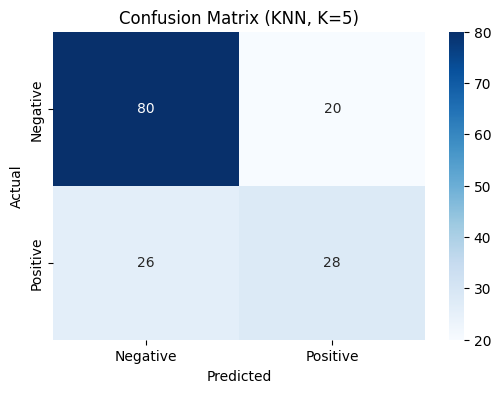

In [33]:
# 8. Plot a confusion matrix and visualize it using a heatmap

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6,4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Negative','Positive'],
            yticklabels=['Negative','Positive'])
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix (KNN, K=5)")
plt.show()

In [34]:
acc = accuracy_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)

print(f"Accuracy: {acc:.4f}")
print(f"F1-Score: {f1:.4f}")

Accuracy: 0.7013
F1-Score: 0.5490


In [35]:
print("\nClassification Report:")
print(classification_report(y_test, y_pred, target_names=['Negative','Positive']))


Classification Report:
              precision    recall  f1-score   support

    Negative       0.75      0.80      0.78       100
    Positive       0.58      0.52      0.55        54

    accuracy                           0.70       154
   macro avg       0.67      0.66      0.66       154
weighted avg       0.69      0.70      0.70       154



In [36]:
# 1. Load the Iris dataset and display the shape of the dataset.
df_iris = pd.read_csv("/content/Iris.csv")
df_iris.shape

(150, 6)

In [37]:
df_iris.head()

,Id,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species
0,1,5.1,3.5,1.4,0.2,Iris-setosa
1,2,4.9,3.0,1.4,0.2,Iris-setosa
2,3,4.7,3.2,1.3,0.2,Iris-setosa
3,4,4.6,3.1,1.5,0.2,Iris-setosa
4,5,5.0,3.6,1.4,0.2,Iris-setosa


In [38]:
# 2. Rename the columns: ‘sepal length (cm)’ to ‘SepalLength’, ‘sepal width (cm)’ to ‘SepalWidth’, ‘petal length (cm)’ to ‘PetalLength’, and ‘petal width (cm)’ to ‘PetalWidth’.
df_iris = df_iris.rename(columns={
    'SepalLengthCm': 'SepalLength',
    'SepalWidthCm': 'SepalWidth',
    'PetalLengthCm': 'PetalLength',
    'PetalWidthCm': 'PetalWidth'
})
df_iris.head()

,Id,SepalLength,SepalWidth,PetalLength,PetalWidth,Species
0,1,5.1,3.5,1.4,0.2,Iris-setosa
1,2,4.9,3.0,1.4,0.2,Iris-setosa
2,3,4.7,3.2,1.3,0.2,Iris-setosa
3,4,4.6,3.1,1.5,0.2,Iris-setosa
4,5,5.0,3.6,1.4,0.2,Iris-setosa


In [39]:
# 3. Use the describe() function to display the summary statistics of the Iris dataset
df_iris.describe()

,Id,SepalLength,SepalWidth,PetalLength,PetalWidth
count,150.000000,150.000000,150.000000,150.000000,150.000000
mean,75.500000,5.843333,3.054000,3.758667,1.198667
std,43.445368,0.828066,0.433594,1.764420,0.763161
min,1.000000,4.300000,2.000000,1.000000,0.100000
25%,38.250000,5.100000,2.800000,1.600000,0.300000
50%,75.500000,5.800000,3.000000,4.350000,1.300000
75%,112.750000,6.400000,3.300000,5.100000,1.800000
max,150.000000,7.900000,4.400000,6.900000,2.500000


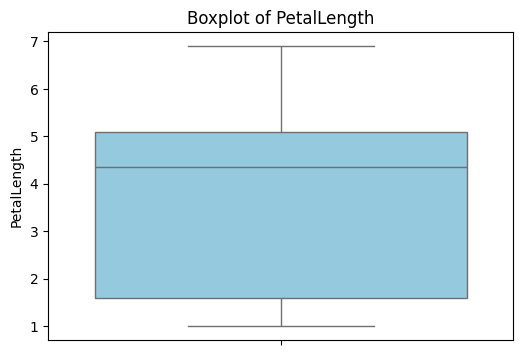

In [40]:
# 4. Visualize the distribution of ‘PetalLength’ using a boxplot
plt.figure(figsize=(6,4))
sns.boxplot(y=df_iris['PetalLength'], color='skyblue')
plt.title("Boxplot of PetalLength")
plt.ylabel("PetalLength")
plt.show()

In [42]:
# 5. Split the dataset into 80% training and 20% testing sets.
X = df_iris[['SepalLength', 'SepalWidth', 'PetalLength', 'PetalWidth']]
y = df_iris['Species']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("\nTrain size:", X_train.shape, " Test size:", X_test.shape)


Train size: (120, 4)  Test size: (30, 4)


In [44]:
# 6. Standardize features using MinMaxScaler
scaler = MinMaxScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("\nFirst 5 rows of scaled training data:")
print(X_train_scaled[:5])


First 5 rows of scaled training data:
[[0.02777778 0.375      0.05172414 0.04166667]
 [0.16666667 0.20833333 0.5862069  0.66666667]
 [0.69444444 0.33333333 0.63793103 0.54166667]
 [0.16666667 0.45833333 0.06896552 0.        ]
 [0.33333333 0.20833333 0.5        0.5       ]]


In [45]:
# 7. Train Gaussian Naive Bayes
nb = GaussianNB()
nb.fit(X_train_scaled, y_train)

# Predictions
y_pred1 = nb.predict(X_test_scaled)

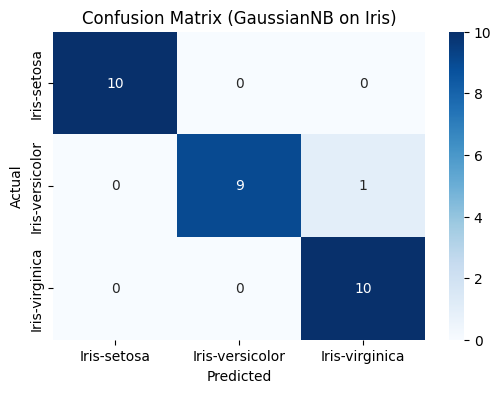

In [53]:
cm = confusion_matrix(y_test, y_pred1)

# Heatmap
plt.figure(figsize=(6,4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=df_iris["Species"].unique(),
            yticklabels=df_iris["Species"].unique())
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix (GaussianNB on Iris)")
plt.show()


In [55]:
print("Accuracy:", accuracy_score(y_test, y_pred1))
print("Recall:", recall_score(y_test, y_pred1, average='macro'))

Accuracy: 0.9666666666666667
Recall: 0.9666666666666667


In [56]:
print("\nClassification Report:")
print(classification_report(y_test, y_pred1))


Classification Report:
                 precision    recall  f1-score   support

    Iris-setosa       1.00      1.00      1.00        10
Iris-versicolor       1.00      0.90      0.95        10
 Iris-virginica       0.91      1.00      0.95        10

       accuracy                           0.97        30
      macro avg       0.97      0.97      0.97        30
   weighted avg       0.97      0.97      0.97        30

